<a href="https://colab.research.google.com/github/SUSHMITHA193/Internship-on-Data-Science/blob/main/Week_3_Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

%pip install -q pandas numpy scipy matplotlib seaborn


In [3]:

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

uploaded = files.upload()

# Extract ZIP files if your download is a ZIP archive
for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall("/content/weather_dataset")

# Find CSV files in the uploaded or extracted files
csv_files = glob.glob("/content/*.csv")
csv_files += glob.glob(
    "/content/weather_dataset/**/*.csv",
    recursive=True
)

# Remove duplicate paths
csv_files = list(dict.fromkeys(csv_files))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Upload the downloaded CSV or ZIP file."
    )

print("Available CSV files:")
for i, path in enumerate(csv_files):
    print(i, path)


Saving Bias_correction_ucl.csv to Bias_correction_ucl (1).csv
Available CSV files:
0 /content/Bias_correction_ucl (1).csv
1 /content/Bias_correction_ucl.csv


In [5]:

# Select the correct dataset CSV if multiple files are listed
matching_files = [
    f for f in csv_files
    if "bias_correction" in os.path.basename(f).lower()
]

DATA_FILE = matching_files[0] if matching_files else csv_files[0]

df = pd.read_csv(DATA_FILE)

# Standardize column names
df.columns = [
    str(c).strip().replace("\ufeff", "")
    for c in df.columns
]

print("Loaded file:", DATA_FILE)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())
display(df.info())


Loaded file: /content/Bias_correction_ucl (1).csv
Dataset shape: (7752, 25)

Column names:
['station', 'Date', 'Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin', 'LDAPS_RHmax', 'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS', 'LDAPS_LH', 'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4', 'LDAPS_PPT1', 'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4', 'lat', 'lon', 'DEM', 'Slope', 'Solar radiation', 'Next_Tmax', 'Next_Tmin']


,station,Date,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,...,LDAPS_PPT2,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation,Next_Tmax,Next_Tmin
0,1.0,2013-06-30,28.7,21.4,58.255688,91.116364,28.074101,23.006936,6.818887,69.451805,...,0.0,0.0,0.0,37.6046,126.991,212.3350,2.7850,5992.895996,29.1,21.2
1,2.0,2013-06-30,31.9,21.6,52.263397,90.604721,29.850689,24.035009,5.691890,51.937448,...,0.0,0.0,0.0,37.6046,127.032,44.7624,0.5141,5869.312500,30.5,22.5
2,3.0,2013-06-30,31.6,23.3,48.690479,83.973587,30.091292,24.565633,6.138224,20.573050,...,0.0,0.0,0.0,37.5776,127.058,33.3068,0.2661,5863.555664,31.1,23.9
3,4.0,2013-06-30,32.0,23.4,58.239788,96.483688,29.704629,23.326177,5.650050,65.727144,...,0.0,0.0,0.0,37.6450,127.022,45.7160,2.5348,5856.964844,31.7,24.3
4,5.0,2013-06-30,31.4,21.9,56.174095,90.155128,29.113934,23.486480,5.735004,107.965535,...,0.0,0.0,0.0,37.5507,127.135,35.0380,0.5055,5859.552246,31.2,22.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7752 entries, 0 to 7751
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   station           7750 non-null   float64
 1   Date              7750 non-null   object 
 2   Present_Tmax      7682 non-null   float64
 3   Present_Tmin      7682 non-null   float64
 4   LDAPS_RHmin       7677 non-null   float64
 5   LDAPS_RHmax       7677 non-null   float64
 6   LDAPS_Tmax_lapse  7677 non-null   float64
 7   LDAPS_Tmin_lapse  7677 non-null   float64
 8   LDAPS_WS          7677 non-null   float64
 9   LDAPS_LH          7677 non-null   float64
 10  LDAPS_CC1         7677 non-null   float64
 11  LDAPS_CC2         7677 non-null   float64
 12  LDAPS_CC3         7677 non-null   float64
 13  LDAPS_CC4         7677 non-null   float64
 14  LDAPS_PPT1        7677 non-null   float64
 15  LDAPS_PPT2        7677 non-null   float64
 16  LDAPS_PPT3        7677 non-null   float64


None

In [6]:

# Confirm that the required columns exist
required_columns = [
    "station",
    "LDAPS_Tmax_lapse",
    "Next_Tmax"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Actual columns are: {df.columns.tolist()}"
    )

# Convert relevant columns to numeric
for col in ["station", "LDAPS_Tmax_lapse", "Next_Tmax"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert date when available
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove missing values needed for this analysis
before = len(df)

clean_df = df.dropna(
    subset=["station", "LDAPS_Tmax_lapse", "Next_Tmax"]
).copy()

# Remove implausible temperatures and invalid station numbers
clean_df = clean_df[
    clean_df["station"].between(1, 25)
    & clean_df["LDAPS_Tmax_lapse"].between(-50, 60)
    & clean_df["Next_Tmax"].between(-50, 60)
].copy()

print("Rows before cleaning:", before)
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", before - len(clean_df))
print("Stations available:", clean_df["station"].nunique())

display(clean_df[
    ["station", "LDAPS_Tmax_lapse", "Next_Tmax"]
].describe())


Rows before cleaning: 7752
Rows after cleaning: 7648
Rows removed: 104
Stations available: 25


,station,LDAPS_Tmax_lapse,Next_Tmax
count,7648.000000,7648.000000,7648.000000
mean,13.008237,29.616654,30.238010
std,7.214062,2.942035,3.111153
min,1.000000,17.624954,17.400000
25%,7.000000,27.675512,28.200000
50%,13.000000,29.705437,30.400000
75%,19.000000,31.710469,32.600000
max,25.000000,38.542255,38.900000


In [7]:

# Automatically select the station with the most complete records
station_counts = clean_df["station"].value_counts()
selected_station = station_counts.index[0]

analysis_df = clean_df[
    clean_df["station"] == selected_station
].copy()

analysis_df = analysis_df.sort_values("Date") if "Date" in analysis_df.columns else analysis_df.copy()

# Split observations using the median forecast temperature
forecast_median = analysis_df["LDAPS_Tmax_lapse"].median()

analysis_df["forecast_group"] = np.where(
    analysis_df["LDAPS_Tmax_lapse"] <= forecast_median,
    "Lower forecast",
    "Higher forecast"
)

lower = analysis_df.loc[
    analysis_df["forecast_group"] == "Lower forecast",
    "Next_Tmax"
].dropna()

higher = analysis_df.loc[
    analysis_df["forecast_group"] == "Higher forecast",
    "Next_Tmax"
].dropna()

print("Selected station:", selected_station)
print("Number of observations:", len(analysis_df))
print("Median forecast maximum temperature:", round(forecast_median, 2))
print("Lower-forecast group size:", len(lower))
print("Higher-forecast group size:", len(higher))

display(analysis_df.head())


Selected station: 1.0
Number of observations: 307
Median forecast maximum temperature: 28.04
Lower-forecast group size: 154
Higher-forecast group size: 153


,station,Date,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,...,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation,Next_Tmax,Next_Tmin,forecast_group
0,1.0,2013-06-30,28.7,21.4,58.255688,91.116364,28.074101,23.006936,6.818887,69.451805,...,0.000000,0.000000,37.6046,126.991,212.335,2.785,5992.895996,29.1,21.2,Higher forecast
25,1.0,2013-07-01,28.3,21.2,72.798576,97.642792,25.276716,21.142562,15.608045,64.914946,...,0.237004,0.848082,37.6046,126.991,212.335,2.785,5987.718750,24.8,18.7,Lower forecast
50,1.0,2013-07-02,24.4,20.6,55.647278,98.370041,27.785497,19.561770,11.168633,74.625920,...,0.000000,0.000000,37.6046,126.991,212.335,2.785,5981.979492,28.1,17.8,Lower forecast
75,1.0,2013-07-03,27.9,17.9,76.017967,95.990532,28.125651,21.982579,10.546499,39.809905,...,0.000000,0.051695,37.6046,126.991,212.335,2.785,5975.676270,25.2,20.8,Higher forecast
100,1.0,2013-07-04,24.9,21.5,55.888565,97.402481,30.458252,22.077078,7.393145,63.599636,...,0.000000,0.000000,37.6046,126.991,212.335,2.785,5968.809082,28.0,19.7,Higher forecast


In [8]:

summary = (
    analysis_df.groupby("forecast_group")["Next_Tmax"]
    .agg(
        Sample_Size="count",
        Mean="mean",
        Median="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    )
    .reindex(["Lower forecast", "Higher forecast"])
)

print("DESCRIPTIVE STATISTICS")
display(summary.round(3))

print("\nForecast temperature summary:")
display(
    analysis_df["LDAPS_Tmax_lapse"]
    .describe()
    .to_frame(name="Forecast maximum temperature")
)


DESCRIPTIVE STATISTICS


,Sample_Size,Mean,Median,Standard_Deviation,Minimum,Maximum
forecast_group,,,,,,
Lower forecast,154,25.453,25.5,2.348,17.4,30.5
Higher forecast,153,29.526,29.7,1.888,24.9,33.4



Forecast temperature summary:


,Forecast maximum temperature
count,307.000000
mean,27.852246
std,2.769762
min,17.624954
25%,26.005571
50%,28.037432
75%,29.820779
max,33.360508


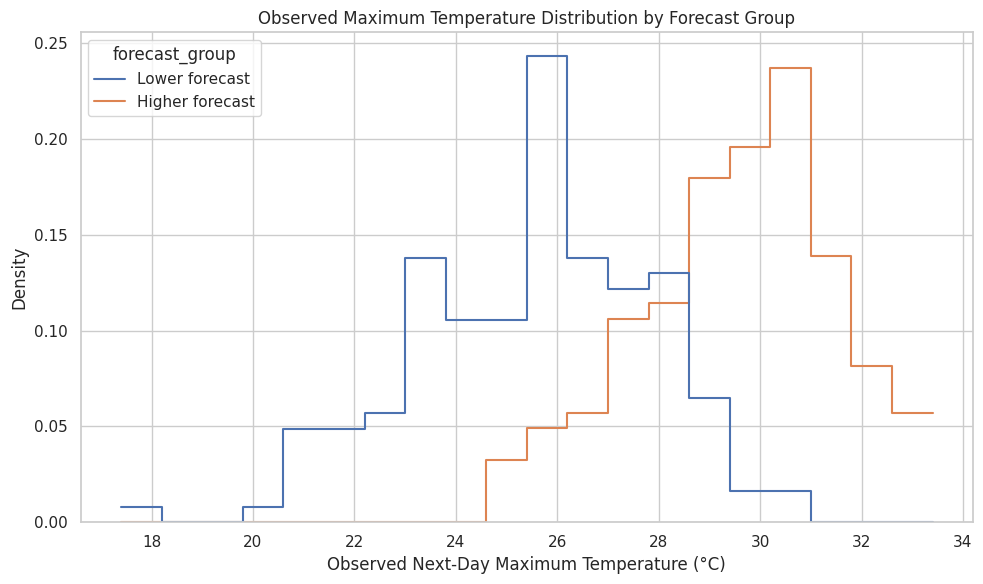

In [9]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=analysis_df,
    x="Next_Tmax",
    hue="forecast_group",
    hue_order=["Lower forecast", "Higher forecast"],
    bins=20,
    element="step",
    stat="density",
    common_norm=False,
    fill=False
)

plt.title("Observed Maximum Temperature Distribution by Forecast Group")
plt.xlabel("Observed Next-Day Maximum Temperature (°C)")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig("01_temperature_distribution.png", dpi=300)
plt.show()


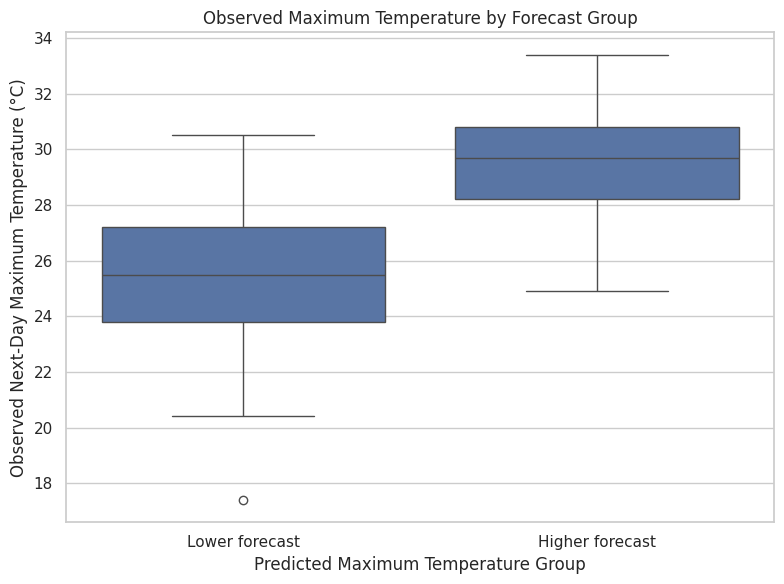

In [10]:

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=analysis_df,
    x="forecast_group",
    y="Next_Tmax",
    order=["Lower forecast", "Higher forecast"]
)

plt.title("Observed Maximum Temperature by Forecast Group")
plt.xlabel("Predicted Maximum Temperature Group")
plt.ylabel("Observed Next-Day Maximum Temperature (°C)")
plt.tight_layout()
plt.savefig("02_temperature_boxplot.png", dpi=300)
plt.show()


In [11]:

# Hypotheses:
# H0: Mean observed maximum temperature is equal in both groups.
# H1: Mean observed maximum temperature differs between the groups.

alpha = 0.05

n1, n2 = len(lower), len(higher)
mean1, mean2 = lower.mean(), higher.mean()
var1, var2 = lower.var(ddof=1), higher.var(ddof=1)

# Welch's independent two-sample t-test
test_result = stats.ttest_ind(
    lower,
    higher,
    equal_var=False,
    alternative="two-sided"
)

t_statistic = test_result.statistic
p_value = test_result.pvalue

# Mean difference: lower forecast group minus higher forecast group
mean_difference = mean1 - mean2

# Standard error and Welch degrees of freedom
standard_error = np.sqrt(var1 / n1 + var2 / n2)

df_num = (var1 / n1 + var2 / n2) ** 2
df_den = (
    (var1 / n1) ** 2 / (n1 - 1)
    + (var2 / n2) ** 2 / (n2 - 1)
)
degrees_freedom = df_num / df_den

# 95% confidence interval for mean difference
critical_t = stats.t.ppf(1 - alpha / 2, degrees_freedom)

ci_lower = mean_difference - critical_t * standard_error
ci_upper = mean_difference + critical_t * standard_error

print("=" * 55)
print("WELCH'S INDEPENDENT TWO-SAMPLE T-TEST")
print("=" * 55)
print(f"Selected station: {selected_station}")
print(f"Lower-forecast sample size: {n1}")
print(f"Higher-forecast sample size: {n2}")
print(f"Lower-forecast group mean: {mean1:.3f} °C")
print(f"Higher-forecast group mean: {mean2:.3f} °C")
print(f"Mean difference (lower - higher): {mean_difference:.3f} °C")
print(f"Standard error: {standard_error:.4f}")
print(f"t-statistic: {t_statistic:.4f}")
print(f"Degrees of freedom: {degrees_freedom:.2f}")
print(f"p-value: {p_value:.8g}")
print(f"95% confidence interval: ({ci_lower:.3f}, {ci_upper:.3f}) °C")

if p_value < alpha:
    decision = "Reject the null hypothesis"
    print("\nDecision:", decision)
    print(
        "There is statistically significant evidence of a difference "
        "in the group mean observed temperatures."
    )
else:
    decision = "Fail to reject the null hypothesis"
    print("\nDecision:", decision)
    print(
        "There is insufficient statistical evidence of a difference "
        "in the group mean observed temperatures."
    )

print("=" * 55)


WELCH'S INDEPENDENT TWO-SAMPLE T-TEST
Selected station: 1.0
Lower-forecast sample size: 154
Higher-forecast sample size: 153
Lower-forecast group mean: 25.453 °C
Higher-forecast group mean: 29.526 °C
Mean difference (lower - higher): -4.073 °C
Standard error: 0.2431
t-statistic: -16.7530
Degrees of freedom: 292.35
p-value: 1.2613053e-44
95% confidence interval: (-4.551, -3.594) °C

Decision: Reject the null hypothesis
There is statistically significant evidence of a difference in the group mean observed temperatures.


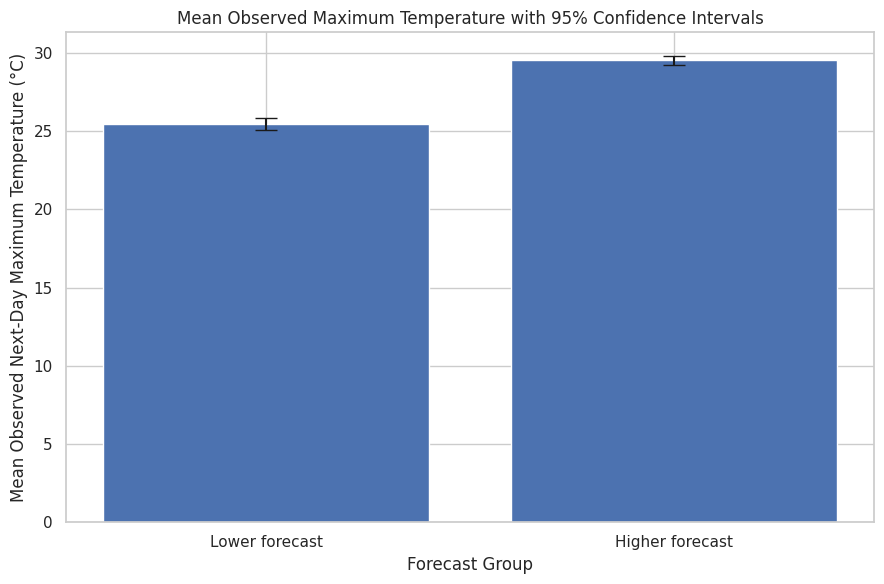

In [12]:

group_data = [
    ("Lower forecast", lower),
    ("Higher forecast", higher)
]

labels = []
means = []
errors = []

for label, values in group_data:
    n = len(values)
    mean = values.mean()
    standard_error_group = stats.sem(values)
    critical = stats.t.ppf(0.975, n - 1)
    margin = critical * standard_error_group

    labels.append(label)
    means.append(mean)
    errors.append(margin)

plt.figure(figsize=(9, 6))

plt.bar(labels, means, yerr=errors, capsize=8)

plt.title("Mean Observed Maximum Temperature with 95% Confidence Intervals")
plt.xlabel("Forecast Group")
plt.ylabel("Mean Observed Next-Day Maximum Temperature (°C)")
plt.tight_layout()
plt.savefig("03_mean_temperature_ci.png", dpi=300)
plt.show()


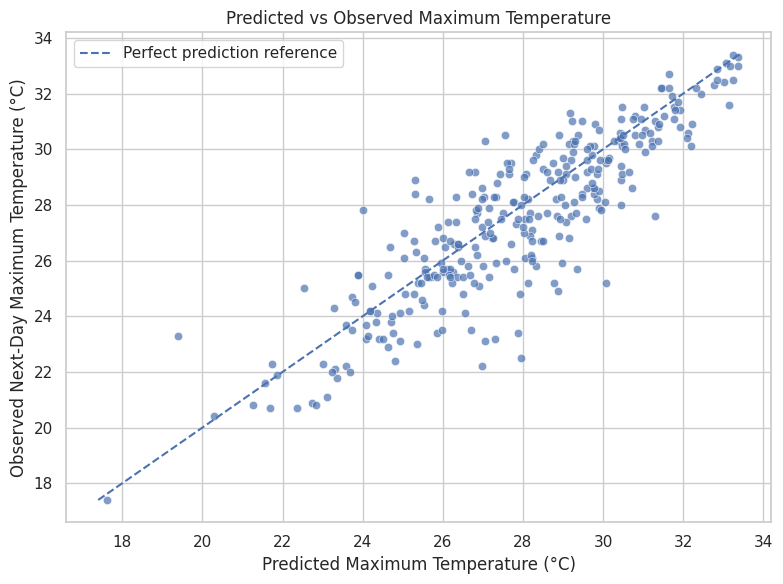

Pearson correlation: 0.8761
Correlation p-value: 1.2568955e-98


In [13]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=analysis_df,
    x="LDAPS_Tmax_lapse",
    y="Next_Tmax",
    alpha=0.7
)

# Reference line: predicted temperature equals observed temperature
min_temp = min(
    analysis_df["LDAPS_Tmax_lapse"].min(),
    analysis_df["Next_Tmax"].min()
)
max_temp = max(
    analysis_df["LDAPS_Tmax_lapse"].max(),
    analysis_df["Next_Tmax"].max()
)

plt.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    linestyle="--",
    label="Perfect prediction reference"
)

plt.title("Predicted vs Observed Maximum Temperature")
plt.xlabel("Predicted Maximum Temperature (°C)")
plt.ylabel("Observed Next-Day Maximum Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.savefig("04_forecast_vs_observed.png", dpi=300)
plt.show()

# Calculate Pearson correlation as a supplementary analysis
correlation, correlation_p = stats.pearsonr(
    analysis_df["LDAPS_Tmax_lapse"],
    analysis_df["Next_Tmax"]
)

print(f"Pearson correlation: {correlation:.4f}")
print(f"Correlation p-value: {correlation_p:.8g}")


In [14]:

# Save descriptive statistics
summary.to_csv("descriptive_statistics.csv")

# Save statistical test results
results = pd.DataFrame([{
    "Selected Station": selected_station,
    "Forecast Median (°C)": forecast_median,
    "Lower Group Sample Size": n1,
    "Higher Group Sample Size": n2,
    "Lower Group Mean (°C)": mean1,
    "Higher Group Mean (°C)": mean2,
    "Mean Difference (°C)": mean_difference,
    "t-statistic": t_statistic,
    "Degrees of Freedom": degrees_freedom,
    "p-value": p_value,
    "95% CI Lower": ci_lower,
    "95% CI Upper": ci_upper,
    "Significance Level": alpha,
    "Decision": decision,
    "Pearson Correlation": correlation,
    "Correlation p-value": correlation_p
}])

results.to_csv("hypothesis_test_results.csv", index=False)

# Save cleaned observations
analysis_df.to_csv("cleaned_weather_data.csv", index=False)

# Create a report interpretation using actual results
if p_value < alpha:
    conclusion = (
        "The null hypothesis was rejected at the 5% significance level. "
        "The data provide evidence of a difference in mean observed "
        "maximum temperatures between the two forecast groups."
    )
else:
    conclusion = (
        "The null hypothesis was not rejected at the 5% significance "
        "level. The data do not provide sufficient evidence of a "
        "difference in mean observed maximum temperatures between "
        "the two forecast groups."
    )

interpretation = f"""
WEEK 3: STATISTICAL ANALYSIS AND HYPOTHESIS TESTING

Research question:
Is the mean observed next-day maximum temperature different between
the lower and higher predicted maximum-temperature groups?

Dataset:
UCI Machine Learning Repository - Bias Correction of Numerical
Prediction Model Temperature Forecast.

The analysis used station {selected_station}, with {n1} observations
in the lower-forecast group and {n2} observations in the
higher-forecast group. The groups were defined using the median
predicted maximum temperature of {forecast_median:.2f} degrees Celsius.

The mean observed maximum temperature was {mean1:.3f} degrees Celsius
in the lower-forecast group and {mean2:.3f} degrees Celsius in the
higher-forecast group.

Welch's independent two-sample t-test produced a t-statistic of
{t_statistic:.4f}, approximately {degrees_freedom:.2f} degrees of
freedom, and a p-value of {p_value:.8g}.

The estimated mean difference (lower minus higher) was
{mean_difference:.3f} degrees Celsius, with a 95% confidence interval
from {ci_lower:.3f} to {ci_upper:.3f} degrees Celsius.

Decision: {decision}.

{conclusion}

Supplementary analysis:
The Pearson correlation between predicted and observed maximum
temperature was {correlation:.4f}, with a p-value of
{correlation_p:.8g}.

Limitations:
The comparison is observational, not experimental. Daily observations
may be temporally correlated, and results from one station may not
generalize to other stations. The forecast groups are defined using
the predicted temperature, so a difference in observed temperature
does not by itself demonstrate forecast accuracy or causation.
"""

with open(
    "results_interpretation.txt", "w", encoding="utf-8"
) as f:
    f.write(interpretation)

print("Results saved successfully!")
print("\nFiles created:")
print("- descriptive_statistics.csv")
print("- hypothesis_test_results.csv")
print("- cleaned_weather_data.csv")
print("- results_interpretation.txt")
print("- 01_temperature_distribution.png")
print("- 02_temperature_boxplot.png")
print("- 03_mean_temperature_ci.png")
print("- 04_forecast_vs_observed.png")

display(results.T.rename(columns={0: "Result"}))


Results saved successfully!

Files created:
- descriptive_statistics.csv
- hypothesis_test_results.csv
- cleaned_weather_data.csv
- results_interpretation.txt
- 01_temperature_distribution.png
- 02_temperature_boxplot.png
- 03_mean_temperature_ci.png
- 04_forecast_vs_observed.png


,Result
Selected Station,1.0
Forecast Median (°C),28.037432
Lower Group Sample Size,154
Higher Group Sample Size,153
Lower Group Mean (°C),25.453247
Higher Group Mean (°C),29.526144
Mean Difference (°C),-4.072897
t-statistic,-16.752955
Degrees of Freedom,292.353068
p-value,0.0


In [15]:

from google.colab import files
import shutil

output_files = [
    "descriptive_statistics.csv",
    "hypothesis_test_results.csv",
    "cleaned_weather_data.csv",
    "results_interpretation.txt",
    "01_temperature_distribution.png",
    "02_temperature_boxplot.png",
    "03_mean_temperature_ci.png",
    "04_forecast_vs_observed.png"
]

with zipfile.ZipFile(
    "Week3_Statistical_Analysis_Results.zip", "w"
) as zipf:
    for filename in output_files:
        if os.path.exists(filename):
            zipf.write(filename)

files.download("Week3_Statistical_Analysis_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>